# Knowledge Discovery Project
## Discovering Patterns of Limited Internet Availability

### Importing needed libraries

In [ ]:
import pandas as pd
import numpy as np
from datetime import datetime, timedelta
import random
from sklearn.preprocessing import LabelEncoder
import matplotlib.pyplot as plt
import scipy.stats as stats
import seaborn as sns
import scipy.stats as stats
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
import warnings
warnings.filterwarnings('ignore')
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, AdaBoostClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.metrics import (classification_report, confusion_matrix,
                              accuracy_score, precision_score, recall_score,
                              f1_score, roc_auc_score, roc_curve)
from sklearn.metrics import ConfusionMatrixDisplay
import time
import pickle

### Generating Dataset

In [ ]:
NUM_RECORDS = 15000
START_DATE = datetime(2025, 1, 1)

areas = {
    "Gaza City": "Urban",
    "Jabalia": "Crowded",
    "Khan Younis": "Urban",
    "Rafah": "Crowded",
    "Deir Al-Balah": "Urban",
    "Beach Camp": "Crowded"
}

time_quality_factor = {
    "Morning": 0.7,
    "Afternoon": 0.6,
    "Evening": 0.5,
    "Night": 0.3
}

def get_time_period(hour):
    if 6 <= hour < 12:
        return "Morning"
    elif 12 <= hour < 17:
        return "Afternoon"
    elif 17 <= hour < 22:
        return "Evening"
    else:
        return "Night"

def generate_quality(prob):
    if prob > 0.65:
        return "High"
    elif prob > 0.4:
        return "Medium"
    else:
        return "Low"

data = []

for _ in range(NUM_RECORDS):
    random_minutes = random.randint(0, 60 * 24 * 90)
    timestamp = START_DATE + timedelta(minutes=random_minutes)

    hour = timestamp.hour
    day_of_week = timestamp.strftime("%A")
    time_period = get_time_period(hour)

    area = random.choice(list(areas.keys()))
    area_type = areas[area]

    base_prob = time_quality_factor[time_period]
    if area_type == "Crowded":
        base_prob -= 0.15

    base_prob = max(0.05, min(base_prob, 0.9))

    connection = np.random.choice([1, 0], p=[base_prob, 1 - base_prob])

    if connection == 1:
        quality = generate_quality(base_prob)
        disconnects = np.random.poisson(2)
    else:
        quality = "Low"
        disconnects = np.random.randint(3, 8)

    data.append([
        timestamp,
        hour,
        day_of_week,
        area,
        area_type,
        connection,
        quality,
        disconnects
    ])

columns = [
    "timestamp",
    "hour",
    "day_of_week",
    "area",
    "area_type",
    "connection",
    "quality",
    "disconnects"
]

df = pd.DataFrame(data, columns=columns)
df.to_csv("internet_availability_dataset.csv", index=False)

df.head(), df.shape

(            timestamp  hour day_of_week         area area_type  connection  \
 0 2025-02-18 08:15:00     8     Tuesday  Khan Younis     Urban           1   
 1 2025-02-09 22:11:00    22      Sunday        Rafah   Crowded           0   
 2 2025-01-06 08:31:00     8      Monday   Beach Camp   Crowded           1   
 3 2025-03-05 23:57:00    23   Wednesday    Gaza City     Urban           0   
 4 2025-03-31 23:20:00    23      Monday   Beach Camp   Crowded           0   
 
   quality  disconnects  
 0    High            2  
 1     Low            3  
 2  Medium            1  
 3     Low            6  
 4     Low            3  ,
 (15000, 8))

In [ ]:
# Save the data in CSV file
df.to_csv("internet_availability_dataset.csv", index=False)

### Data Understanding

In [ ]:
df.dtypes

timestamp      datetime64[ns]
hour                    int64
day_of_week            object
area                   object
area_type              object
connection              int32
quality                object
disconnects             int64
dtype: object

### Data Preprocessing

In [ ]:
df.isnull().sum()

timestamp      0
hour           0
day_of_week    0
area           0
area_type      0
connection     0
quality        0
disconnects    0
dtype: int64

#### Checking Inconsistencies

In [ ]:
df["day_of_week"].unique()

array(['Tuesday', 'Sunday', 'Monday', 'Wednesday', 'Thursday', 'Saturday',
       'Friday'], dtype=object)

In [ ]:
df["area"].unique()

array(['Khan Younis', 'Rafah', 'Beach Camp', 'Gaza City', 'Deir Al-Balah',
       'Jabalia'], dtype=object)

In [ ]:
df["area_type"].unique()

array(['Urban', 'Crowded'], dtype=object)

In [ ]:
df["quality"].unique()

array(['High', 'Low', 'Medium'], dtype=object)

### Encoding Categorical Variables

In [ ]:
le_quality = LabelEncoder()
df["quality_encoded"] = le_quality.fit_transform(df["quality"])

In [ ]:
df[["quality", "quality_encoded"]].head(10)

,quality,quality_encoded
0,High,0
1,Low,1
2,Medium,2
3,Low,1
4,Low,1
5,Low,1
6,Low,1
7,Low,1
8,Low,1
9,Low,1


In [ ]:
le_area = LabelEncoder()
df["area_encoded"] = le_area.fit_transform(df["area"])

In [ ]:
df[["area", "area_encoded"]].head(10)

,area,area_encoded
0,Khan Younis,4
1,Rafah,5
2,Beach Camp,0
3,Gaza City,2
4,Beach Camp,0
5,Rafah,5
6,Gaza City,2
7,Beach Camp,0
8,Gaza City,2
9,Khan Younis,4


In [ ]:
le_day = LabelEncoder()
df["day_encoded"] = le_day.fit_transform(df["day_of_week"])

In [ ]:
df[["day_of_week", "day_encoded"]].head(15)

,day_of_week,day_encoded
0,Tuesday,5
1,Sunday,3
2,Monday,1
3,Wednesday,6
4,Monday,1
5,Monday,1
6,Thursday,4
7,Thursday,4
8,Saturday,2
9,Thursday,4


### Handling Outliers

In [ ]:
df["disconnects"].describe()

count    15000.000000
mean         3.698400
std          2.035448
min          0.000000
25%          2.000000
50%          4.000000
75%          5.000000
max         11.000000
Name: disconnects, dtype: float64

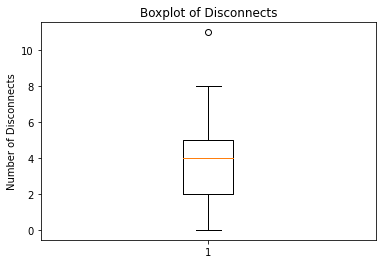

In [ ]:
plt.boxplot(df["disconnects"])
plt.title("Boxplot of Disconnects")
plt.ylabel("Number of Disconnects")
plt.show()

# Exploratory Data Analysis


###  Descriptive Statistics

>  Measures of Central Tendency

In [ ]:
# We will focus on disconnects and connection
general_stats = df[['disconnects', 'connection']].describe().loc[['mean', '50%']]
general_stats.rename(index={'50%': 'median'}, inplace=True)
general_stats.loc['mode'] = df[['disconnects', 'connection']].mode().iloc[0]

print("Measures of Central Tendency")
print(general_stats)
print("\n")

# Analysis accoording to Area > Urban vs Crowded
area_comparison = df.groupby('area_type')[['disconnects', 'connection']].mean()

print("Average (outages and availability) by region type")
print(area_comparison)
print("\n")

quality_mode = df.groupby('area_type')['quality'].agg(pd.Series.mode)

print(" Most common quality by region")
print(quality_mode)

Measures of Central Tendency
        disconnects  connection
mean         3.6984    0.432267
median       4.0000    0.000000
mode         3.0000    0.000000


Average (outages and availability) by region type
           disconnects  connection
area_type                         
Crowded       3.893451     0.36044
Urban         3.505829     0.50318


 Most common quality by region
area_type
Crowded    Low
Urban      Low
Name: quality, dtype: object


 Notes :
- Connection state >>
- The internet is only available 43% of the time overall.
- The "unavailability" status is the most frequent and prevalent in the data, accurately reflecting a resource-limited environment.
- Area Type  >>
- Connection : In urban areas, availability approaches 50%, while in crowded areas it drops to 36%. This confirms the presence of network load due to population density.
- Disconnects: Congested areas suffer from a higher disconnection rate of 3.9 compared to 3.5 in urban areas.
- Quality Analysis >>
-  The pattern in both types is Low.
 This proves that even when a connection is available, it is often of poor quality.

>  Measures of Variability

In [ ]:
# Variability of disconnection
range_val = df["disconnects"].max() - df["disconnects"].min()
variance_val = df["disconnects"].var()
std_dev_val = df["disconnects"].std()

print(f"Range of Disconnects: {range_val}")
print(f"Variance of Disconnects: {variance_val:.2f}")
print(f"Standard Deviation of Disconnects: {std_dev_val:.2f}")

Range of Disconnects: 11
Variance of Disconnects: 4.14
Standard Deviation of Disconnects: 2.04


-  Dispersion analysis of the interruption column revealed significant variation in service quality, with a standard deviation of 2.05, indicating an unstable user experience.
-  A range of up to 9 confirms instances of connectivity degradation, reinforcing the importance of using clustering techniques to identify temporal and spatial patterns.

> Measures of Shape

In [ ]:
# Calculating the skewness and kurtosis of the disconnect
skew_val = df["disconnects"].skew()

kurt_val = df["disconnects"].kurtosis()

print(f"Skewness of Disconnects: {skew_val:.2f}")
print(f"Kurtosis of Disconnects: {kurt_val:.2f}")

Skewness of Disconnects: 0.00
Kurtosis of Disconnects: -0.96


- Skewness = 0.01  indicates that the distribution of interrupts is almost symmetrical, meaning there is no bias towards a particular side, and that low and high interrupts occur equally frequently, indicating a systematic problem across connection attempts.

- Kurtosis = -0.98 indicates a platykurtic or flat distribution, meaning there is no sharp peak, but rather a broad, flat distribution. This confirms that the values ​​(number of breaks) are evenly distributed over a wide range, facilitating the separation of clusters using the clustering algorithm.

## Inferential Statistics

- Confidence Intervals

We will use a 95% confidence , which is the global standard for academic research.

In [ ]:
# Basic Data
sample_mean = df["disconnects"].mean()
sample_std = df["disconnects"].std()
n = len(df)

# Standard Error
std_error = sample_std / np.sqrt(n)

# Confidence Interval (95%)
conf_int = stats.t.interval(0.95, df=n-1, loc=sample_mean, scale=std_error)
print(f"95% Confidence Interval for Disconnects: {conf_int}")

95% Confidence Interval for Disconnects: (3.665824023902644, 3.7309759760973558)


- The confidence interval for the breaks (3.66–3.73) is very narrow (~0.06) due to the large sample size (15000),
- which indicates a low margin of error and confirms the reliability of the true mean estimate.

### Data Visualization

- Heatmap for the relationship between variables

In [ ]:
plt.figure(figsize=(10, 8))
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Correlation Heatmap of Project Variables')
plt.show()

TypeError: corr() got an unexpected keyword argument 'numeric_only'

<Figure size 720x576 with 0 Axes>

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# Connection rate by area
area_conn = df.groupby('area')['connection'].mean().sort_values(ascending=True)
axes[0, 0].barh(area_conn.index, area_conn.values, color='teal', alpha=0.7)
axes[0, 0].set_title('Connection Rate by Area', fontweight='bold', fontsize=12)
axes[0, 0].set_xlabel('Connection Rate')
axes[0, 0].grid(axis='x', alpha=0.3)
for i, v in enumerate(area_conn.values):
    axes[0, 0].text(v + 0.01, i, f'{v:.1%}', va='center')

# Average disconnects by area
area_disc = df.groupby('area')['disconnects'].mean().sort_values(ascending=True)
axes[0, 1].barh(area_disc.index, area_disc.values, color='coral', alpha=0.7)
axes[0, 1].set_title('Average Disconnects by Area', fontweight='bold', fontsize=12)
axes[0, 1].set_xlabel('Average Disconnects')
axes[0, 1].grid(axis='x', alpha=0.3)
for i, v in enumerate(area_disc.values):
    axes[0, 1].text(v + 0.1, i, f'{v:.1f}', va='center')

# Quality distribution by area
quality_area = pd.crosstab(df['area'], df['quality'], normalize='index') * 100
quality_area.plot(kind='bar', stacked=True, ax=axes[1, 0],
                  color=['#ff9999','#66b3ff','#99ff99'])
axes[1, 0].set_title('Quality Distribution by Area (%)', fontweight='bold', fontsize=12)
axes[1, 0].set_xlabel('Area')
axes[1, 0].set_ylabel('Percentage')
axes[1, 0].legend(title='Quality', bbox_to_anchor=(1.05, 1), loc='upper left')
axes[1, 0].set_xticklabels(axes[1, 0].get_xticklabels(), rotation=45, ha='right')
axes[1, 0].grid(axis='y', alpha=0.3)

#  Connection success rate by area and area_type
area_type_conn = df.groupby(['area', 'area_type'])['connection'].mean().unstack()
area_type_conn.plot(kind='bar', ax=axes[1, 1], color=['steelblue', 'orange'], alpha=0.7)
axes[1, 1].set_title('Connection Rate: Area vs Area Type', fontweight='bold', fontsize=12)
axes[1, 1].set_xlabel('Area')
axes[1, 1].set_ylabel('Connection Rate')
axes[1, 1].legend(title='Area Type')
axes[1, 1].set_xticklabels(axes[1, 1].get_xticklabels(), rotation=45, ha='right')
axes[1, 1].grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Connection rate by day
day_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
day_conn = df.groupby('day_of_week')['connection'].mean().reindex(day_order)
colors_day = ['steelblue' if day not in ['Saturday', 'Sunday'] else 'orange'
              for day in day_order]
axes[0].bar(range(7), day_conn.values, color=colors_day, alpha=0.7, edgecolor='black')
axes[0].set_title('Internet Availability by Day of Week', fontweight='bold', fontsize=12)
axes[0].set_xlabel('Day of Week')
axes[0].set_ylabel('Connection Rate')
axes[0].set_xticks(range(7))
axes[0].set_xticklabels(['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun'])
axes[0].grid(axis='y', alpha=0.3)
axes[0].axhline(y=day_conn.mean(), color='red', linestyle='--',
                label=f'Average: {day_conn.mean():.1%}', linewidth=2)
axes[0].legend()

#  Disconnects by day
day_disc = df.groupby('day_of_week')['disconnects'].mean().reindex(day_order)
axes[1].plot(range(7), day_disc.values, marker='o', linewidth=2,
             markersize=8, color='red')
axes[1].fill_between(range(7), day_disc.values, alpha=0.3, color='red')
axes[1].set_title('Average Disconnects by Day of Week', fontweight='bold', fontsize=12)
axes[1].set_xlabel('Day of Week')
axes[1].set_ylabel('Average Disconnects')
axes[1].set_xticks(range(7))
axes[1].set_xticklabels(['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun'])
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

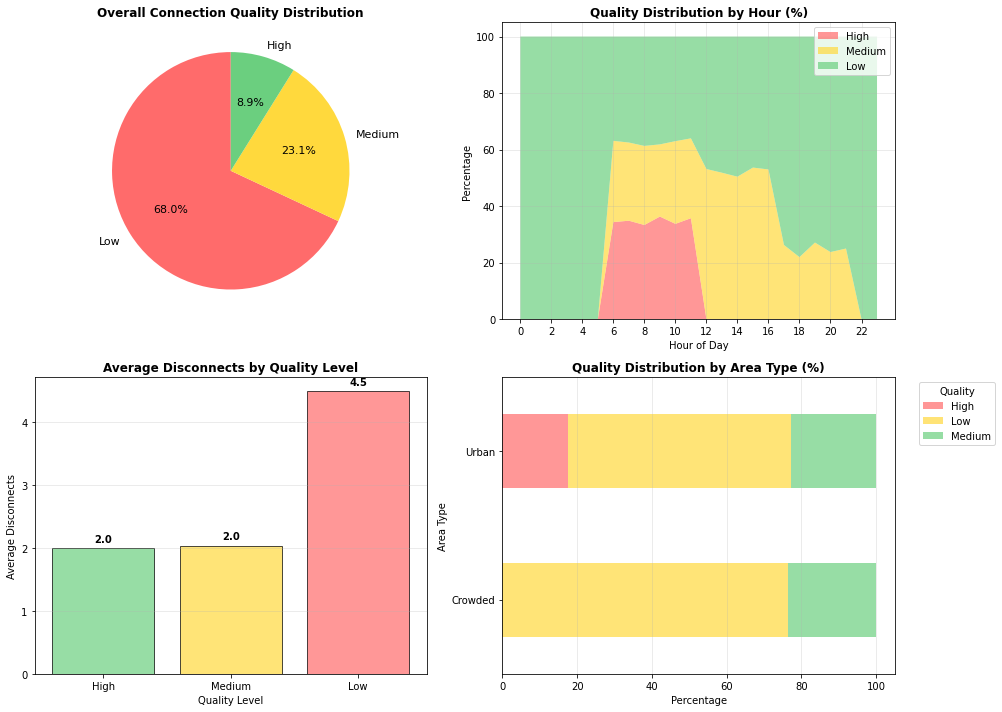

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Quality distribution (overall)
quality_dist = df['quality'].value_counts()
colors_quality = ['#ff6b6b', '#ffd93d', '#6bcf7f']
axes[0, 0].pie(quality_dist.values, labels=quality_dist.index, autopct='%1.1f%%',
               colors=colors_quality, startangle=90, textprops={'fontsize': 11})
axes[0, 0].set_title('Overall Connection Quality Distribution',
                     fontweight='bold', fontsize=12)

# Quality by hour (stacked area)
quality_hour = pd.crosstab(df['hour'], df['quality'], normalize='index') * 100
axes[0, 1].stackplot(quality_hour.index,
                     quality_hour['High'],
                     quality_hour['Medium'],
                     quality_hour['Low'],
                     labels=['High', 'Medium', 'Low'],
                     colors=colors_quality, alpha=0.7)
axes[0, 1].set_title('Quality Distribution by Hour (%)', fontweight='bold', fontsize=12)
axes[0, 1].set_xlabel('Hour of Day')
axes[0, 1].set_ylabel('Percentage')
axes[0, 1].legend(loc='upper right')
axes[0, 1].grid(True, alpha=0.3)
axes[0, 1].set_xticks(range(0, 24, 2))

#  Quality vs Disconnects
quality_disc = df.groupby('quality')['disconnects'].mean().sort_values()
axes[1, 0].bar(quality_disc.index, quality_disc.values,
               color=['#6bcf7f', '#ffd93d', '#ff6b6b'], alpha=0.7, edgecolor='black')
axes[1, 0].set_title('Average Disconnects by Quality Level',
                     fontweight='bold', fontsize=12)
axes[1, 0].set_xlabel('Quality Level')
axes[1, 0].set_ylabel('Average Disconnects')
axes[1, 0].grid(axis='y', alpha=0.3)
for i, v in enumerate(quality_disc.values):
    axes[1, 0].text(i, v + 0.1, f'{v:.1f}', ha='center', fontweight='bold')

#  Quality by area type
quality_areatype = pd.crosstab(df['area_type'], df['quality'], normalize='index') * 100
quality_areatype.plot(kind='barh', stacked=True, ax=axes[1, 1],
                      color=colors_quality, alpha=0.7)
axes[1, 1].set_title('Quality Distribution by Area Type (%)',
                     fontweight='bold', fontsize=12)
axes[1, 1].set_xlabel('Percentage')
axes[1, 1].set_ylabel('Area Type')
axes[1, 1].legend(title='Quality', bbox_to_anchor=(1.05, 1), loc='upper left')
axes[1, 1].grid(axis='x', alpha=0.3)

plt.tight_layout()
plt.show()

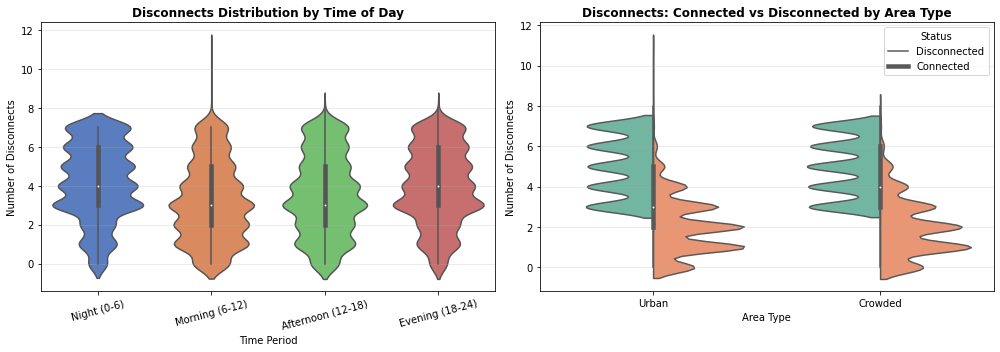

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

#  Disconnects by hour (grouped)
df['hour_group'] = pd.cut(df['hour'], bins=[0, 6, 12, 18, 24],
                           labels=['Night (0-6)', 'Morning (6-12)',
                                   'Afternoon (12-18)', 'Evening (18-24)'],
                           include_lowest=True)
sns.violinplot(data=df, x='hour_group', y='disconnects', palette='muted', ax=axes[0])
axes[0].set_title('Disconnects Distribution by Time of Day', fontweight='bold', fontsize=12)
axes[0].set_xlabel('Time Period')
axes[0].set_ylabel('Number of Disconnects')
axes[0].tick_params(axis='x', rotation=15)
axes[0].grid(axis='y', alpha=0.3)

#  Connection comparison
connection_data = df[['connection', 'area_type']].copy()
connection_data['Status'] = connection_data['connection'].map({0: 'Disconnected', 1: 'Connected'})
sns.violinplot(data=df, x='area_type', y='disconnects', hue='connection',
               split=True, palette='Set2', ax=axes[1])
axes[1].set_title('Disconnects: Connected vs Disconnected by Area Type',
                  fontweight='bold', fontsize=12)
axes[1].set_xlabel('Area Type')
axes[1].set_ylabel('Number of Disconnects')
axes[1].legend(title='Status', labels=['Disconnected', 'Connected'])
axes[1].grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

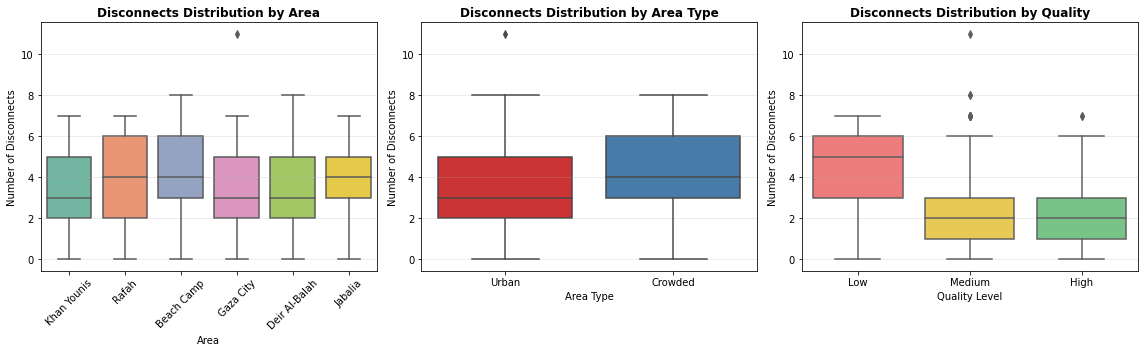

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# Disconnects by area
sns.boxplot(data=df, x='area', y='disconnects', palette='Set2', ax=axes[0])
axes[0].set_title('Disconnects Distribution by Area', fontweight='bold', fontsize=12)
axes[0].set_xlabel('Area')
axes[0].set_ylabel('Number of Disconnects')
axes[0].tick_params(axis='x', rotation=45)
axes[0].grid(axis='y', alpha=0.3)

# Disconnects by area type
sns.boxplot(data=df, x='area_type', y='disconnects', palette='Set1', ax=axes[1])
axes[1].set_title('Disconnects Distribution by Area Type', fontweight='bold', fontsize=12)
axes[1].set_xlabel('Area Type')
axes[1].set_ylabel('Number of Disconnects')
axes[1].grid(axis='y', alpha=0.3)

# Disconnects by quality
sns.boxplot(data=df, x='quality', y='disconnects',
            palette={'Low': '#ff6b6b', 'Medium': '#ffd93d', 'High': '#6bcf7f'},
            ax=axes[2], order=['Low', 'Medium', 'High'])
axes[2].set_title('Disconnects Distribution by Quality', fontweight='bold', fontsize=12)
axes[2].set_xlabel('Quality Level')
axes[2].set_ylabel('Number of Disconnects')
axes[2].grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

- Line Plot for "Changes in interruptions across the hours"

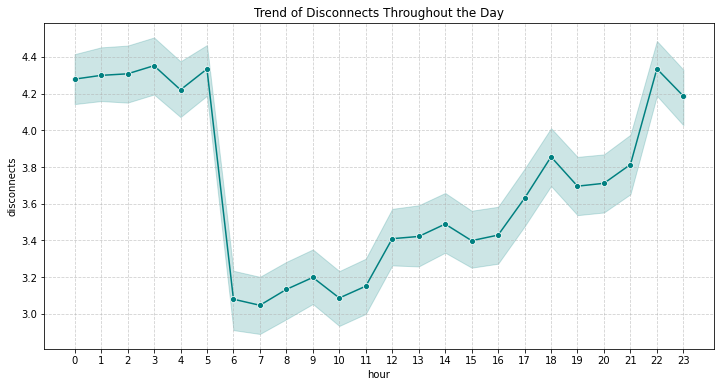

In [ ]:
plt.figure(figsize=(12, 6))
sns.lineplot(x='hour', y='disconnects', data=df, marker='o', color='teal')
plt.xticks(range(0, 24))
plt.grid(True, linestyle='--', alpha=0.6)
plt.title('Trend of Disconnects Throughout the Day')
plt.show()

- Average Internet Availability by Hour

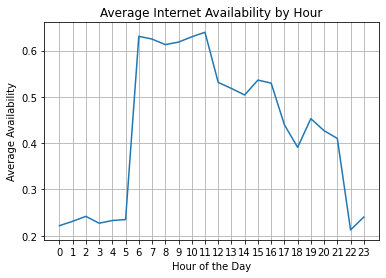

In [ ]:
availability_by_hour = df.groupby('hour')['connection'].mean()
plt.plot(availability_by_hour.index, availability_by_hour.values)
plt.title('Average Internet Availability by Hour')
plt.xlabel('Hour of the Day')
plt.ylabel('Average Availability')
plt.xticks(range(0, 24))
plt.grid()
plt.show()

- Availability by day and hour (Heatmap Pivot)

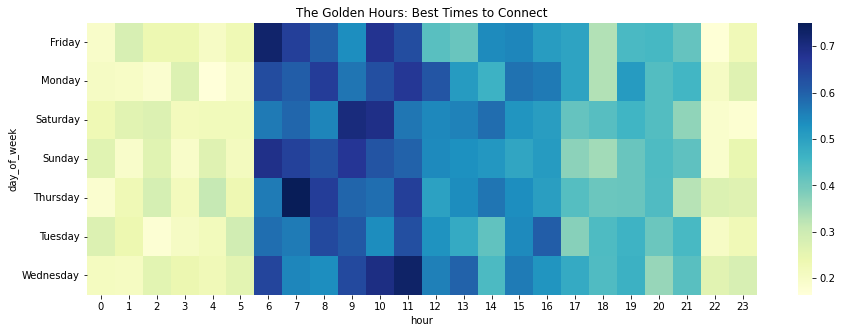

In [ ]:
pivot = df.pivot_table(index='day_of_week', columns='hour', values='connection', aggfunc='mean')

plt.figure(figsize=(15, 5))
sns.heatmap(pivot, cmap='YlGnBu', annot=False)
plt.title('The Golden Hours: Best Times to Connect')
plt.show()

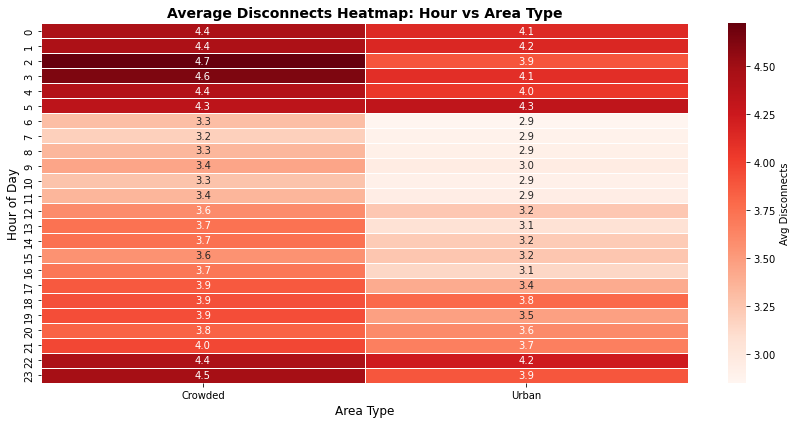

In [ ]:
# Average Disconnects Heatmap: Hour vs Area Type
plt.figure(figsize=(12, 6))
pivot_disconnects = df.pivot_table(values='disconnects',
                                    index='hour',
                                    columns='area_type',
                                    aggfunc='mean')
sns.heatmap(pivot_disconnects, annot=True, fmt=".1f", cmap='Reds',
            linewidths=0.5, cbar_kws={'label': 'Avg Disconnects'})
plt.title('Average Disconnects Heatmap: Hour vs Area Type',
          fontsize=14, fontweight='bold')
plt.xlabel('Area Type', fontsize=12)
plt.ylabel('Hour of Day', fontsize=12)
plt.tight_layout()
plt.show()

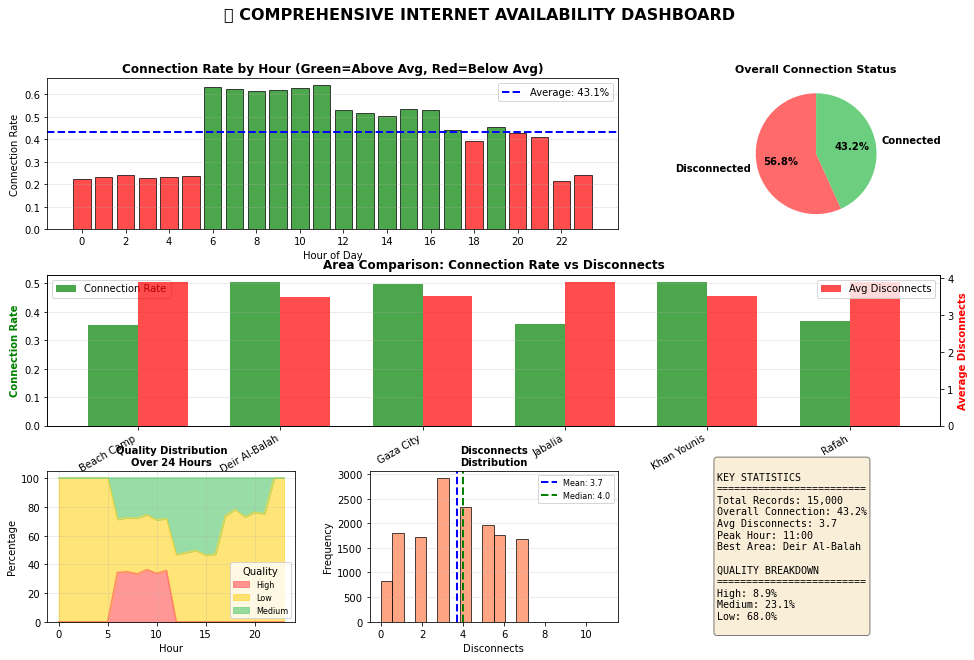

In [ ]:
fig = plt.figure(figsize=(16, 10))
gs = fig.add_gridspec(3, 3, hspace=0.3, wspace=0.3)

# Top insights - Best/Worst hours
ax1 = fig.add_subplot(gs[0, :2])
hourly_conn = df.groupby('hour')['connection'].mean()
colors_hour = ['green' if v > hourly_conn.mean() else 'red' for v in hourly_conn.values]
ax1.bar(hourly_conn.index, hourly_conn.values, color=colors_hour, alpha=0.7, edgecolor='black')
ax1.axhline(y=hourly_conn.mean(), color='blue', linestyle='--', linewidth=2,
            label=f'Average: {hourly_conn.mean():.1%}')
ax1.set_title('Connection Rate by Hour (Green=Above Avg, Red=Below Avg)',
              fontweight='bold', fontsize=12)
ax1.set_xlabel('Hour of Day')
ax1.set_ylabel('Connection Rate')
ax1.legend()
ax1.grid(axis='y', alpha=0.3)
ax1.set_xticks(range(0, 24, 2))

#  Connection status pie
ax2 = fig.add_subplot(gs[0, 2])
conn_status = df['connection'].value_counts()
ax2.pie(conn_status.values, labels=['Disconnected', 'Connected'],
        autopct='%1.1f%%', colors=['#ff6b6b', '#6bcf7f'],
        startangle=90, textprops={'fontsize': 10, 'fontweight': 'bold'})
ax2.set_title('Overall Connection Status', fontweight='bold', fontsize=11)

# Area comparison
ax3 = fig.add_subplot(gs[1, :])
area_comparison = df.groupby('area').agg({
    'connection': 'mean',
    'disconnects': 'mean'
}).reset_index()
x = np.arange(len(area_comparison))
width = 0.35
ax3.bar(x - width/2, area_comparison['connection'], width,
        label='Connection Rate', color='green', alpha=0.7)
ax3_twin = ax3.twinx()
ax3_twin.bar(x + width/2, area_comparison['disconnects'], width,
             label='Avg Disconnects', color='red', alpha=0.7)
ax3.set_xlabel('Area', fontweight='bold')
ax3.set_ylabel('Connection Rate', color='green', fontweight='bold')
ax3_twin.set_ylabel('Average Disconnects', color='red', fontweight='bold')
ax3.set_title('Area Comparison: Connection Rate vs Disconnects',
              fontweight='bold', fontsize=12)
ax3.set_xticks(x)
ax3.set_xticklabels(area_comparison['area'], rotation=30, ha='right')
ax3.legend(loc='upper left')
ax3_twin.legend(loc='upper right')
ax3.grid(axis='y', alpha=0.3)

# Quality over time
ax4 = fig.add_subplot(gs[2, 0])
quality_time = df.groupby('hour')['quality'].value_counts(normalize=True).unstack(fill_value=0) * 100
quality_time.plot(kind='area', stacked=True, ax=ax4,
                  color=colors_quality, alpha=0.7)
ax4.set_title('Quality Distribution\nOver 24 Hours', fontweight='bold', fontsize=10)
ax4.set_xlabel('Hour')
ax4.set_ylabel('Percentage')
ax4.legend(title='Quality', fontsize=8)
ax4.grid(True, alpha=0.3)

#  Disconnects distribution
ax5 = fig.add_subplot(gs[2, 1])
ax5.hist(df['disconnects'], bins=20, color='coral', alpha=0.7, edgecolor='black')
ax5.axvline(df['disconnects'].mean(), color='blue', linestyle='--', linewidth=2,
            label=f'Mean: {df["disconnects"].mean():.1f}')
ax5.axvline(df['disconnects'].median(), color='green', linestyle='--', linewidth=2,
            label=f'Median: {df["disconnects"].median():.1f}')
ax5.set_title('Disconnects\nDistribution', fontweight='bold', fontsize=10)
ax5.set_xlabel('Disconnects')
ax5.set_ylabel('Frequency')
ax5.legend(fontsize=8)
ax5.grid(axis='y', alpha=0.3)

# Summary stats
ax6 = fig.add_subplot(gs[2, 2])
ax6.axis('off')
summary_text = f"""
KEY STATISTICS
{'='*25}
Total Records: {len(df):,}
Overall Connection: {df['connection'].mean():.1%}
Avg Disconnects: {df['disconnects'].mean():.1f}
Peak Hour: {hourly_conn.idxmax()}:00
Best Area: {area_comparison.loc[area_comparison['connection'].idxmax(), 'area']}

QUALITY BREAKDOWN
{'='*25}
High: {(df['quality']=='High').sum()/len(df)*100:.1f}%
Medium: {(df['quality']=='Medium').sum()/len(df)*100:.1f}%
Low: {(df['quality']=='Low').sum()/len(df)*100:.1f}%
"""
ax6.text(0.1, 0.5, summary_text, fontsize=10, family='monospace',
         verticalalignment='center', bbox=dict(boxstyle='round',
         facecolor='wheat', alpha=0.5))

plt.suptitle('📊 COMPREHENSIVE INTERNET AVAILABILITY DASHBOARD',
             fontsize=16, fontweight='bold', y=0.98)
plt.tight_layout()
plt.show()

In [ ]:
print(" FINAL INSIGHTS ")

# Top 3 and Worst 3 Hours
best_hours = hourly_conn.nlargest(3)
worst_hours = hourly_conn.nsmallest(3)

print("\nTIME-BASED INSIGHTS:")
print(f" Best Hours for Connection:")
for hour, rate in best_hours.items():
    print(f"     • {hour:02d}:00 - {rate:.1%} availability")

print(f"\n   Worst Hours for Connection:")
for hour, rate in worst_hours.items():
    print(f"     • {hour:02d}:00 - {rate:.1%} availability")

# Comparing regions
print("\n AREA-BASED INSIGHTS:")
area_stats = df.groupby('area').agg({
    'connection': 'mean',
    'disconnects': 'mean',
    'quality': lambda x: (x=='High').sum() / len(x) * 100
}).round(2)
area_stats.columns = ['Conn_Rate', 'Avg_Disconnects', 'High_Quality_%']
area_stats = area_stats.sort_values('Conn_Rate', ascending=False)

for area in area_stats.index:
    print(f"\n  📌 {area}:")
    print(f"     • Connection Rate: {area_stats.loc[area, 'Conn_Rate']:.1%}")
    print(f"     • Avg Disconnects: {area_stats.loc[area, 'Avg_Disconnects']:.1f}")
    print(f"     • High Quality %: {area_stats.loc[area, 'High_Quality_%']:.1f}%")

# Comparing the type of region
print("\n AREA TYPE INSIGHTS:")
for area_type in df['area_type'].unique():
    subset = df[df['area_type'] == area_type]
    print(f"\n  {area_type} Areas:")
    print(f"     • Connection Rate: {subset['connection'].mean():.1%}")
    print(f"     • Avg Disconnects: {subset['disconnects'].mean():.1f}")
    print(f"     • High Quality: {(subset['quality']=='High').sum()/len(subset)*100:.1f}%")

# Weekly patterns
print("\n WEEKLY PATTERNS:")
weekend = df[df['day_of_week'].isin(['Saturday', 'Sunday'])]
weekday = df[~df['day_of_week'].isin(['Saturday', 'Sunday'])]
print(f"  Weekdays (Mon-Fri):")
print(f"     • Connection Rate: {weekday['connection'].mean():.1%}")
print(f"     • Avg Disconnects: {weekday['disconnects'].mean():.1f}")
print(f"\n  Weekends (Sat-Sun):")
print(f"     • Connection Rate: {weekend['connection'].mean():.1%}")
print(f"     • Avg Disconnects: {weekend['disconnects'].mean():.1f}")

print(" RECOMMENDATIONS FOR USERS")
print("\n1. TIMING OPTIMIZATION:")
print(f"   ✓ Schedule important tasks during hours: {', '.join([f'{h}:00' for h in best_hours.index])}")
print(f"   ✗ Avoid critical work during hours: {', '.join([f'{h}:00' for h in worst_hours.index])}")

print("\n2. LOCATION OPTIMIZATION:")
best_area = area_stats.index[0]
print(f"   ✓ Best connectivity in: {best_area}")
print(f"   ✓ Consider relocating important work to areas with higher connectivity")

print("\n3. QUALITY EXPECTATIONS:")
high_quality_pct = (df['quality']=='High').sum() / len(df) * 100
print(f"   • Expect high quality connection only {high_quality_pct:.1f}% of the time")
print(f"   • Plan for potential disconnects (avg {df['disconnects'].mean():.1f} per session)")

 FINAL INSIGHTS 

TIME-BASED INSIGHTS:
 Best Hours for Connection:
     • 11:00 - 64.0% availability
     • 06:00 - 63.1% availability
     • 10:00 - 63.0% availability

   Worst Hours for Connection:
     • 22:00 - 21.2% availability
     • 00:00 - 22.2% availability
     • 03:00 - 22.7% availability

 AREA-BASED INSIGHTS:

  📌 Deir Al-Balah:
     • Connection Rate: 51.0%
     • Avg Disconnects: 3.5
     • High Quality %: 18.0%

  📌 Khan Younis:
     • Connection Rate: 51.0%
     • Avg Disconnects: 3.5
     • High Quality %: 18.1%

  📌 Gaza City:
     • Connection Rate: 50.0%
     • Avg Disconnects: 3.5
     • High Quality %: 16.7%

  📌 Rafah:
     • Connection Rate: 37.0%
     • Avg Disconnects: 3.9
     • High Quality %: 0.0%

  📌 Jabalia:
     • Connection Rate: 36.0%
     • Avg Disconnects: 3.9
     • High Quality %: 0.0%

  📌 Beach Camp:
     • Connection Rate: 35.0%
     • Avg Disconnects: 3.9
     • High Quality %: 0.0%

 AREA TYPE INSIGHTS:

  Urban Areas:
     • Connection Ra

##  Modeling

Selected features for clustering: ['hour', 'disconnects', 'area_encoded', 'day_encoded', 'connection']
Dataset shape: (15000, 5)
✓ Features standardized (mean=0, std=1)


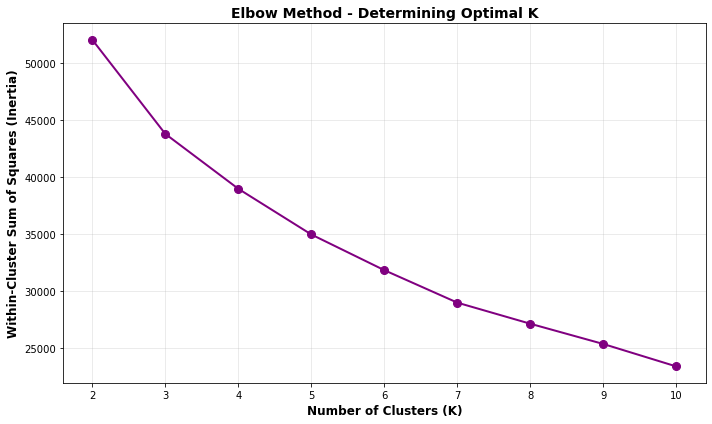


Inertia values for different K:
  K=2: Inertia=52077.80
  K=3: Inertia=43817.54
  K=4: Inertia=39000.60
  K=5: Inertia=34991.30
  K=6: Inertia=31858.44
  K=7: Inertia=29009.26
  K=8: Inertia=27158.22
  K=9: Inertia=25381.47
  K=10: Inertia=23411.12


In [ ]:
# APPLY DATA MINING TECHNIQUE
#  Feature Selection
clustering_features = ['hour', 'disconnects', 'area_encoded', 'day_encoded', 'connection']
X = df[clustering_features].copy()
print(f"Selected features for clustering: {clustering_features}")
print(f"Dataset shape: {X.shape}")

# Standardization
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
print("✓ Features standardized (mean=0, std=1)")

# Determine Optimal K (Elbow Method)
K_range = range(2, 11)
inertias = []

for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    inertias.append(kmeans.inertia_)

# Elbow Curve
plt.figure(figsize=(10, 6))
plt.plot(K_range, inertias, marker='o', linewidth=2, markersize=8, color='purple')
plt.xlabel('Number of Clusters (K)', fontsize=12, fontweight='bold')
plt.ylabel('Within-Cluster Sum of Squares (Inertia)', fontsize=12, fontweight='bold')
plt.title('Elbow Method - Determining Optimal K', fontsize=14, fontweight='bold')
plt.grid(True, alpha=0.3)
plt.xticks(K_range)
plt.tight_layout()
plt.show()

print("\nInertia values for different K:")
for k, inertia in zip(K_range, inertias):
    print(f"  K={k}: Inertia={inertia:.2f}")

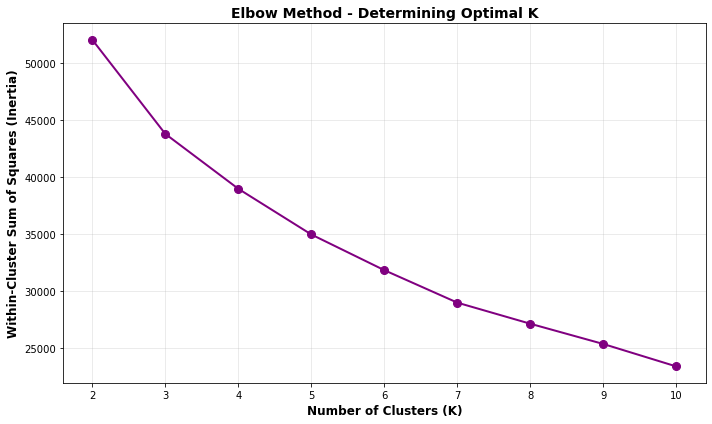

  K=2: Inertia=52077.80
  K=3: Inertia=43817.54
  K=4: Inertia=39000.60
  K=5: Inertia=34991.30
  K=6: Inertia=31858.44
  K=7: Inertia=29009.26
  K=8: Inertia=27158.22
  K=9: Inertia=25381.47
  K=10: Inertia=23411.12

Cluster Distribution:
0    3230
1    3203
2    4237
3    4330
Name: cluster, dtype: int64

Percentage Distribution:
  Cluster 0: 21.5%
  Cluster 1: 21.4%
  Cluster 2: 28.2%
  Cluster 3: 28.9%


In [ ]:
# Elbow Curve
plt.figure(figsize=(10, 6))
plt.plot(K_range, inertias, marker='o', linewidth=2, markersize=8, color='purple')
plt.xlabel('Number of Clusters (K)', fontsize=12, fontweight='bold')
plt.ylabel('Within-Cluster Sum of Squares (Inertia)', fontsize=12, fontweight='bold')
plt.title('Elbow Method - Determining Optimal K', fontsize=14, fontweight='bold')
plt.grid(True, alpha=0.3)
plt.xticks(K_range)
plt.tight_layout()
plt.show()

for k, inertia in zip(K_range, inertias):
    print(f"  K={k}: Inertia={inertia:.2f}")

# Select Optimal K
optimal_k = 4

# Apply K-Means
kmeans_final = KMeans(n_clusters=optimal_k, random_state=42, n_init=10)
df['cluster'] = kmeans_final.fit_predict(X_scaled)

print(f"\nCluster Distribution:")
cluster_dist = df['cluster'].value_counts().sort_index()
print(cluster_dist)
print("\nPercentage Distribution:")
for cluster_id in cluster_dist.index:
    pct = (cluster_dist[cluster_id] / len(df)) * 100
    print(f"  Cluster {cluster_id}: {pct:.1f}%")


 4.1 Cluster Characteristics -
         Avg_Hour  Connection_Rate  Avg_Disconnects  Dominant_Area  \
cluster                                                              
0           11.85             1.00             1.97  Deir Al-Balah   
1           11.82             1.00             1.99    Khan Younis   
2            4.38             0.01             5.01        Jabalia   
3           17.88             0.01             4.98     Beach Camp   

        Dominant_Type  
cluster                
0               Urban  
1               Urban  
2             Crowded  
3             Crowded  

  Initial Cluster Interpretation 
Cluster 0:
  • Size: 3,230 records (21.5%)
  • Avg Hour: 11.9
  • Connection Rate: 100.0%
  • Avg Disconnects: 2.0
  • Dominant Area: Deir Al-Balah
  • Dominant Type: Urban
Cluster 1:
  • Size: 3,203 records (21.4%)
  • Avg Hour: 11.8
  • Connection Rate: 100.0%
  • Avg Disconnects: 2.0
  • Dominant Area: Khan Younis
  • Dominant Type: Urban
Cluster 2:
  • Size: 4,2

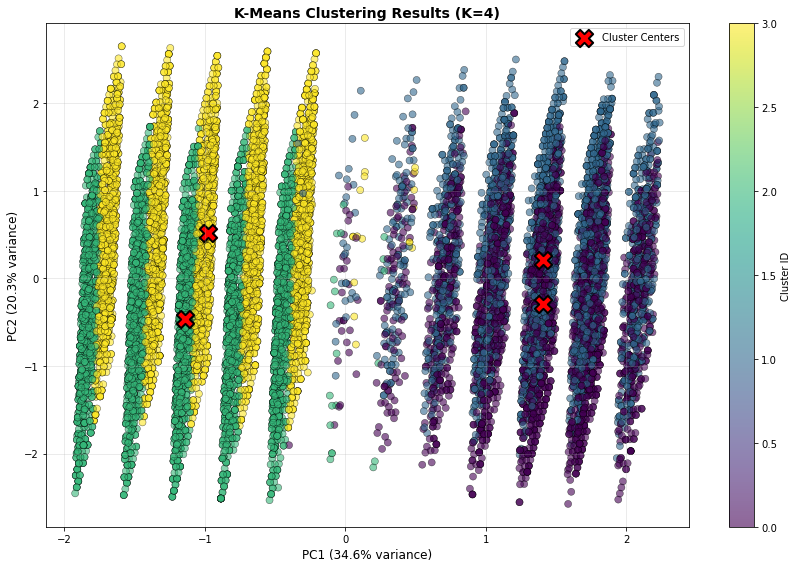

✓ PCA explains 54.9% of total variance


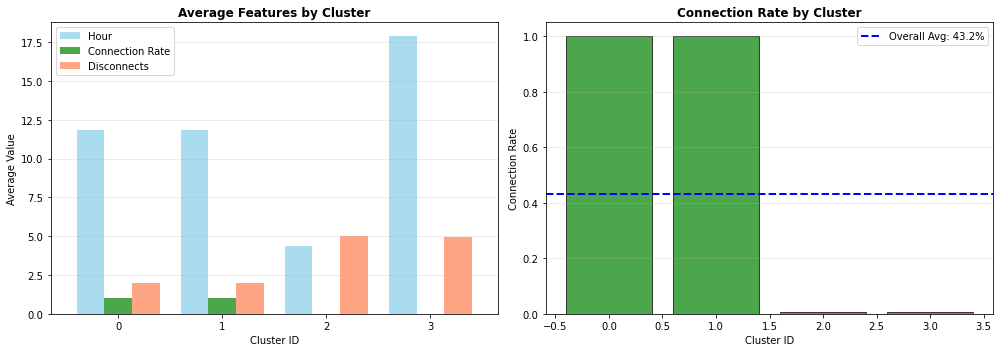

In [ ]:
# CLUSTER ANALYSIS
# Cluster Characteristics
print("\n 4.1 Cluster Characteristics -")
cluster_summary = df.groupby('cluster').agg({
    'hour': 'mean',
    'connection': 'mean',
    'disconnects': 'mean',
    'area': lambda x: x.mode()[0] if len(x.mode()) > 0 else 'Mixed',
    'area_type': lambda x: x.mode()[0] if len(x.mode()) > 0 else 'Mixed'
}).round(2)

cluster_summary.columns = ['Avg_Hour', 'Connection_Rate', 'Avg_Disconnects',
                           'Dominant_Area', 'Dominant_Type']

print(cluster_summary)


# Cluster Interpretation
print("\n  Initial Cluster Interpretation ")
for cluster_id in sorted(df['cluster'].unique()):
    cluster_data = df[df['cluster'] == cluster_id]
    conn_rate = cluster_data['connection'].mean()

    print(f"Cluster {cluster_id}:")
    print(f"  • Size: {len(cluster_data):,} records ({len(cluster_data)/len(df)*100:.1f}%)")
    print(f"  • Avg Hour: {cluster_data['hour'].mean():.1f}")
    print(f"  • Connection Rate: {conn_rate:.1%}")
    print(f"  • Avg Disconnects: {cluster_data['disconnects'].mean():.1f}")
    print(f"  • Dominant Area: {cluster_data['area'].mode()[0]}")
    print(f"  • Dominant Type: {cluster_data['area_type'].mode()[0]}")

# Visualize Clusters (PCA)
print("\nCluster Visualization (PCA) ")
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

plt.figure(figsize=(12, 8))
scatter = plt.scatter(X_pca[:, 0], X_pca[:, 1],
                      c=df['cluster'], cmap='viridis',
                      alpha=0.6, s=50, edgecolors='black', linewidths=0.5)

centers_pca = pca.transform(kmeans_final.cluster_centers_)
plt.scatter(centers_pca[:, 0], centers_pca[:, 1],
            c='red', marker='X', s=300, edgecolors='black', linewidths=2,
            label='Cluster Centers')

plt.colorbar(scatter, label='Cluster ID')
plt.xlabel(f'PC1 ({pca.explained_variance_ratio_[0]:.1%} variance)', fontsize=12)
plt.ylabel(f'PC2 ({pca.explained_variance_ratio_[1]:.1%} variance)', fontsize=12)
plt.title(f'K-Means Clustering Results (K={optimal_k})', fontsize=14, fontweight='bold')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print(f"✓ PCA explains {pca.explained_variance_ratio_.sum():.1%} of total variance")

# Cluster Comparison Visualizations
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Average features by cluster
cluster_avg = df.groupby('cluster')[['hour', 'connection', 'disconnects']].mean()
cluster_avg.plot(kind='bar', ax=axes[0], width=0.8,
                 color=['skyblue', 'green', 'coral'], alpha=0.7)
axes[0].set_title('Average Features by Cluster', fontweight='bold', fontsize=12)
axes[0].set_xlabel('Cluster ID')
axes[0].set_ylabel('Average Value')
axes[0].legend(['Hour', 'Connection Rate', 'Disconnects'])
axes[0].grid(axis='y', alpha=0.3)
axes[0].set_xticklabels(axes[0].get_xticklabels(), rotation=0)

# Connection rate by cluster
conn_by_cluster = df.groupby('cluster')['connection'].mean()
colors = ['green' if v > 0.5 else 'orange' if v > 0.3 else 'red'
          for v in conn_by_cluster.values]
axes[1].bar(conn_by_cluster.index, conn_by_cluster.values,
            color=colors, alpha=0.7, edgecolor='black')
axes[1].set_title('Connection Rate by Cluster', fontweight='bold', fontsize=12)
axes[1].set_xlabel('Cluster ID')
axes[1].set_ylabel('Connection Rate')
axes[1].grid(axis='y', alpha=0.3)
axes[1].axhline(y=df['connection'].mean(), color='blue', linestyle='--',
                linewidth=2, label=f'Overall Avg: {df["connection"].mean():.1%}')
axes[1].legend()

plt.tight_layout()
plt.show()

##  ADDITIONAL MODELING:

###  CLASSIFICATION MODELS


In [ ]:
# Data preparation for classification
features_for_classification = ['hour', 'disconnects', 'area_encoded',
                              'day_encoded', 'quality_encoded']
X_class = df[features_for_classification].copy()
y_class = df['connection'].copy()

print(f"Features shape: {X_class.shape}")
print(f"Target distribution:")
print(y_class.value_counts())
print(f"  - Connected (1): {(y_class==1).sum()} ({(y_class==1).sum()/len(y_class)*100:.1f}%)")
print(f"  - Disconnected (0): {(y_class==0).sum()} ({(y_class==0).sum()/len(y_class)*100:.1f}%)")

# Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X_class, y_class, test_size=0.25, random_state=42, stratify=y_class
)

print(f"Training set: {X_train.shape[0]} samples")
print(f"Testing set: {X_test.shape[0]} samples")
print("✓ Data preparation complete!")

Features shape: (15000, 5)
Target distribution:
0    8516
1    6484
Name: connection, dtype: int64
  - Connected (1): 6484 (43.2%)
  - Disconnected (0): 8516 (56.8%)
Training set: 11250 samples
Testing set: 3750 samples
✓ Data preparation complete!


In [ ]:
print("TRAINING SIMPLE MODELS")
models = {}
predictions = {}
probabilities = {}
training_times = {}

# 1. Naive Bayes
print("\n[1/3] Training Naive Bayes...")
start_time = time.time()
nb_model = GaussianNB()
nb_model.fit(X_train, y_train)
models['Naive Bayes'] = nb_model
predictions['Naive Bayes'] = nb_model.predict(X_test)
probabilities['Naive Bayes'] = nb_model.predict_proba(X_test)[:, 1]
training_times['Naive Bayes'] = time.time() - start_time
print(f"✓ Naive Bayes trained in {training_times['Naive Bayes']:.3f}s")

# 2. K-Nearest Neighbors
print("\n[2/3] Training KNN...")
start_time = time.time()
knn_model = KNeighborsClassifier(n_neighbors=5)
knn_model.fit(X_train, y_train)
models['KNN'] = knn_model
predictions['KNN'] = knn_model.predict(X_test)
probabilities['KNN'] = knn_model.predict_proba(X_test)[:, 1]
training_times['KNN'] = time.time() - start_time
print(f"✓ KNN trained in {training_times['KNN']:.3f}s")

# 3. Decision Tree
print("\n[3/3] Training Decision Tree...")
start_time = time.time()
dt_model = DecisionTreeClassifier(criterion='gini', random_state=42, max_depth=10)
dt_model.fit(X_train, y_train)
models['Decision Tree'] = dt_model
predictions['Decision Tree'] = dt_model.predict(X_test)
probabilities['Decision Tree'] = dt_model.predict_proba(X_test)[:, 1]
training_times['Decision Tree'] = time.time() - start_time
print(f"✓ Decision Tree trained in {training_times['Decision Tree']:.3f}s")

print("✓ Simple models training complete!")

TRAINING SIMPLE MODELS

[1/3] Training Naive Bayes...
✓ Naive Bayes trained in 0.015s

[2/3] Training KNN...
✓ KNN trained in 0.206s

[3/3] Training Decision Tree...
✓ Decision Tree trained in 0.015s
✓ Simple models training complete!


In [ ]:
print("TRAINING LOGISTIC & SVM MODELS")

# 4. Logistic Regression
print("\n[1/2] Training Logistic Regression...")
start_time = time.time()
lr_model = LogisticRegression(random_state=42, solver='liblinear', max_iter=200)
lr_model.fit(X_train, y_train)
models['Logistic Regression'] = lr_model
predictions['Logistic Regression'] = lr_model.predict(X_test)
probabilities['Logistic Regression'] = lr_model.predict_proba(X_test)[:, 1]
training_times['Logistic Regression'] = time.time() - start_time
print(f"✓ Logistic Regression trained in {training_times['Logistic Regression']:.3f}s")

# 5. Support Vector Machine
print("\n[2/2] Training SVM...")
start_time = time.time()
svm_model = SVC(kernel='rbf', C=1.0, random_state=42, probability=True)
svm_model.fit(X_train, y_train)
models['SVM'] = svm_model
predictions['SVM'] = svm_model.predict(X_test)
probabilities['SVM'] = svm_model.predict_proba(X_test)[:, 1]
training_times['SVM'] = time.time() - start_time
print(f"✓ SVM trained in {training_times['SVM']:.3f}s")

print("✓ Logistic & SVM training complete!")

TRAINING LOGISTIC & SVM MODELS

[1/2] Training Logistic Regression...
✓ Logistic Regression trained in 0.020s

[2/2] Training SVM...
✓ SVM trained in 14.801s
✓ Logistic & SVM training complete!


In [ ]:
print("TRAINING ENSEMBLE MODELS")

# 6. Random Forest
print("\n[1/3] Training Random Forest...")
start_time = time.time()
rf_model = RandomForestClassifier(n_estimators=100, random_state=42, max_depth=15)
rf_model.fit(X_train, y_train)
models['Random Forest'] = rf_model
predictions['Random Forest'] = rf_model.predict(X_test)
probabilities['Random Forest'] = rf_model.predict_proba(X_test)[:, 1]
training_times['Random Forest'] = time.time() - start_time
print(f"✓ Random Forest trained in {training_times['Random Forest']:.3f}s")

# 7. Gradient Boosting
print("\n[2/3] Training Gradient Boosting...")
start_time = time.time()
gb_model = GradientBoostingClassifier(n_estimators=100, random_state=42, max_depth=5)
gb_model.fit(X_train, y_train)
models['Gradient Boosting'] = gb_model
predictions['Gradient Boosting'] = gb_model.predict(X_test)
probabilities['Gradient Boosting'] = gb_model.predict_proba(X_test)[:, 1]
training_times['Gradient Boosting'] = time.time() - start_time
print(f"✓ Gradient Boosting trained in {training_times['Gradient Boosting']:.3f}s")

# 8. AdaBoost
print("\n[3/3] Training AdaBoost...")
start_time = time.time()
ada_model = AdaBoostClassifier(n_estimators=100, random_state=42)
ada_model.fit(X_train, y_train)
models['AdaBoost'] = ada_model
predictions['AdaBoost'] = ada_model.predict(X_test)
probabilities['AdaBoost'] = ada_model.predict_proba(X_test)[:, 1]
training_times['AdaBoost'] = time.time() - start_time
print(f"✓ AdaBoost trained in {training_times['AdaBoost']:.3f}s")

print("✓ Ensemble models training complete!")

TRAINING ENSEMBLE MODELS

[1/3] Training Random Forest...
✓ Random Forest trained in 0.685s

[2/3] Training Gradient Boosting...
✓ Gradient Boosting trained in 0.828s

[3/3] Training AdaBoost...
✓ AdaBoost trained in 0.547s
✓ Ensemble models training complete!


In [ ]:
print("FINAL MODEL & EVALUATION SETUP")

# 9. Extra Trees
print("\nTraining Extra Trees...")
start_time = time.time()
et_model = ExtraTreesClassifier(n_estimators=100, random_state=42, max_depth=15)
et_model.fit(X_train, y_train)
models['Extra Trees'] = et_model
predictions['Extra Trees'] = et_model.predict(X_test)
probabilities['Extra Trees'] = et_model.predict_proba(X_test)[:, 1]
training_times['Extra Trees'] = time.time() - start_time
print(f"✓ Extra Trees trained in {training_times['Extra Trees']:.3f}s")

print(f"\n✓ ALL {len(models)} MODELS TRAINED SUCCESSFULLY!")

# Evaluation function (will be used in next cell)
def evaluate_model(name, y_true, y_pred, y_proba):
    accuracy = accuracy_score(y_true, y_pred)
    precision = precision_score(y_true, y_pred, average='binary')
    recall = recall_score(y_true, y_pred, average='binary')
    f1 = f1_score(y_true, y_pred, average='binary')

    try:
        auc = roc_auc_score(y_true, y_proba)
    except:
        auc = 0.0

    return {
        'accuracy': accuracy,
        'precision': precision,
        'recall': recall,
        'f1': f1,
        'auc': auc
    }

print("✓ Evaluation function ready!")

FINAL MODEL & EVALUATION SETUP

Training Extra Trees...
✓ Extra Trees trained in 0.477s

✓ ALL 9 MODELS TRAINED SUCCESSFULLY!
✓ Evaluation function ready!


In [ ]:
print("="*70)
print("MODEL COMPARISON RESULTS")
print("="*70)

# Evaluate all models
results = {}
for name in models.keys():
    metrics = evaluate_model(name, y_test, predictions[name], probabilities[name])
    results[name] = metrics

# Create comparison table
comparison_df = pd.DataFrame(results).T
comparison_df['Training Time (s)'] = pd.Series(training_times)
comparison_df = comparison_df.round(4)
comparison_df = comparison_df.sort_values('f1', ascending=False)

print("\n📊 PERFORMANCE COMPARISON TABLE:")
print(comparison_df)

# Save comparison table
comparison_df.to_csv('classification_models_comparison.csv')
print("\n✓ Comparison table saved: classification_models_comparison.csv")

MODEL COMPARISON RESULTS

📊 PERFORMANCE COMPARISON TABLE:
                     accuracy  precision  recall      f1     auc  \
Gradient Boosting      0.9624     1.0000  0.9130  0.9545  0.9885   
AdaBoost               0.9624     1.0000  0.9130  0.9545  0.9872   
Decision Tree          0.9621     0.9953  0.9167  0.9544  0.9849   
Extra Trees            0.9565     0.9777  0.9204  0.9482  0.9855   
Random Forest          0.9507     0.9597  0.9247  0.9419  0.9844   
KNN                    0.9379     0.9566  0.8970  0.9258  0.9647   
SVM                    0.9208     0.9566  0.8556  0.9033  0.9532   
Naive Bayes            0.8901     1.0000  0.7458  0.8544  0.9782   
Logistic Regression    0.8053     0.7501  0.8242  0.7854  0.9371   

                     Training Time (s)  
Gradient Boosting               0.8276  
AdaBoost                        0.5472  
Decision Tree                   0.0151  
Extra Trees                     0.4772  
Random Forest                   0.6850  
KNN            

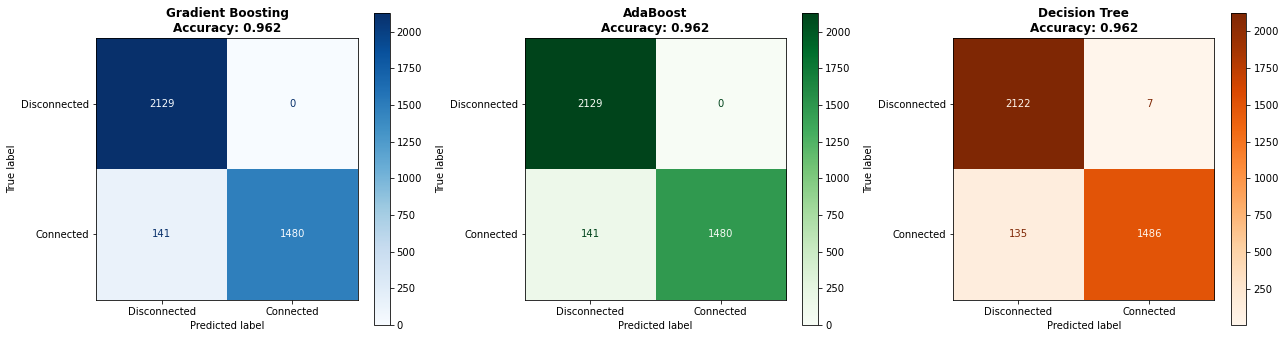

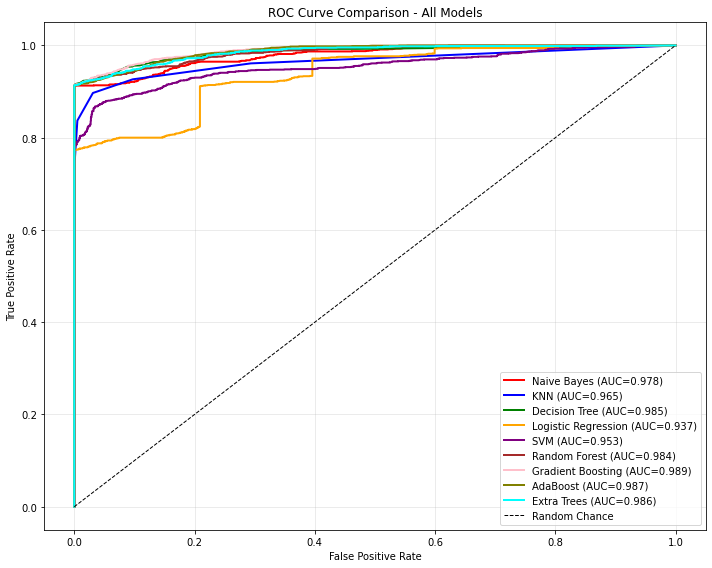

In [ ]:
# Confusion Matrices for Top 3 Models
top_3_models = comparison_df.nlargest(3, 'f1').index.tolist()
color_maps = ['Blues', 'Greens', 'Oranges']

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for i, model_name in enumerate(top_3_models):
    cm = confusion_matrix(y_test, predictions[model_name])
    disp = ConfusionMatrixDisplay(confusion_matrix=cm,
                                  display_labels=["Disconnected", "Connected"])
    disp.plot(cmap=color_maps[i], ax=axes[i])
    axes[i].set_title(f'{model_name}\nAccuracy: {results[model_name]["accuracy"]:.3f}',
                      fontweight='bold')

plt.tight_layout()
plt.show()

# ROC Curve Comparison
plt.figure(figsize=(10, 8))
colors = ['red', 'blue', 'green', 'orange', 'purple', 'brown', 'pink', 'olive', 'cyan']

for i, name in enumerate(models.keys()):
    fpr, tpr, _ = roc_curve(y_test, probabilities[name])
    auc = results[name]['auc']
    plt.plot(fpr, tpr, label=f'{name} (AUC={auc:.3f})',
             color=colors[i], linewidth=2)

plt.plot([0, 1], [0, 1], 'k--', linewidth=1, label='Random Chance')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve Comparison - All Models')
plt.legend(loc='lower right')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

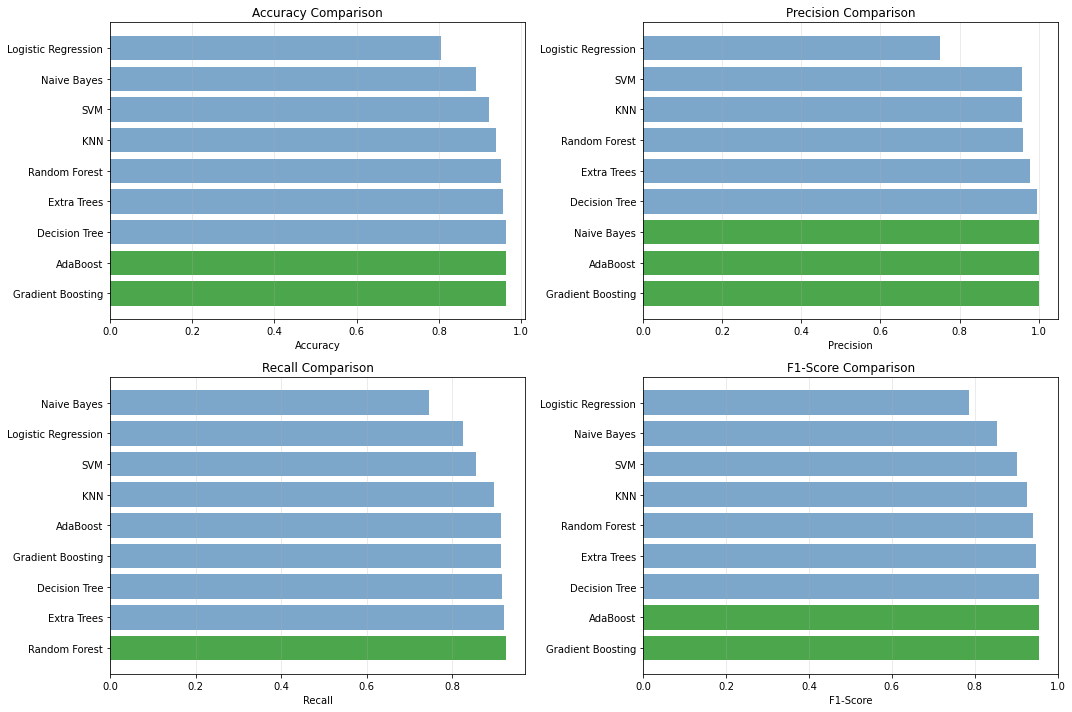

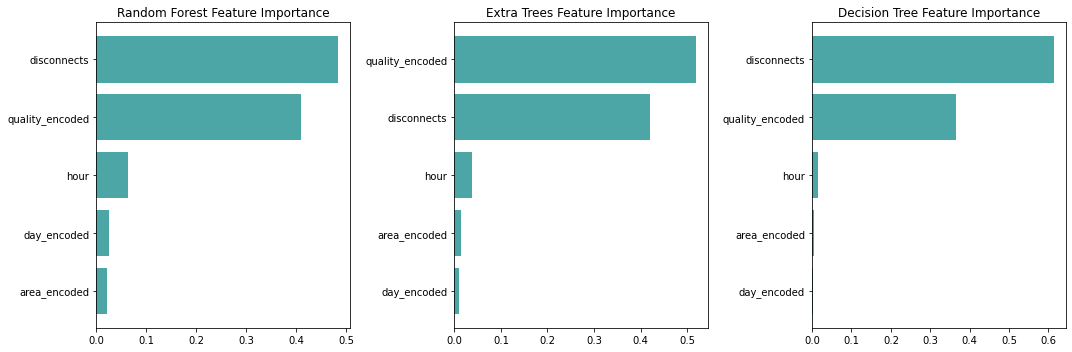

In [ ]:
# Metrics Comparison Charts
fig, axes = plt.subplots(2, 2, figsize=(15, 10))
metrics_to_plot = ['accuracy', 'precision', 'recall', 'f1']
titles = ['Accuracy', 'Precision', 'Recall', 'F1-Score']

for idx, (metric, title) in enumerate(zip(metrics_to_plot, titles)):
    ax = axes[idx // 2, idx % 2]
    metric_values = comparison_df[metric].sort_values(ascending=False)
    colors_bar = ['green' if v == metric_values.max() else 'steelblue'
                  for v in metric_values.values]

    ax.barh(range(len(metric_values)), metric_values.values,
            color=colors_bar, alpha=0.7)
    ax.set_yticks(range(len(metric_values)))
    ax.set_yticklabels(metric_values.index)
    ax.set_xlabel(title)
    ax.set_title(f'{title} Comparison')
    ax.grid(axis='x', alpha=0.3)

plt.tight_layout()
plt.show()

# Feature Importance for Tree-based Models
tree_models = {
    'Random Forest': models['Random Forest'],
    'Extra Trees': models['Extra Trees'],
    'Decision Tree': models['Decision Tree']
}

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for idx, (name, model) in enumerate(tree_models.items()):
    if hasattr(model, 'feature_importances_'):
        importances = model.feature_importances_
        importance_df = pd.DataFrame({
            'Feature': features_for_classification,
            'Importance': importances
        }).sort_values('Importance', ascending=True)

        axes[idx].barh(importance_df['Feature'], importance_df['Importance'],
                       color='teal', alpha=0.7)
        axes[idx].set_title(f'{name} Feature Importance')

plt.tight_layout()
plt.show()

In [ ]:
# Best Model Selection
best_model_name = comparison_df['f1'].idxmax()
best_model = models[best_model_name]
best_metrics = results[best_model_name]

print(f"\n🏆 BEST MODEL: {best_model_name}")
print(f"📊 F1-Score: {best_metrics['f1']:.4f}")
print(f"📈 Accuracy:  {best_metrics['accuracy']:.4f}")
print(f"🎯 ROC AUC:   {best_metrics['auc']:.4f}")
print(f"⏱️  Training Time: {training_times[best_model_name]:.3f}s")

# Top 3 models
print(f"\n🥇 TOP 3 MODELS (F1-Score):")
top_3 = comparison_df.nlargest(3, 'f1')
for i, (model_name, row) in enumerate(top_3.iterrows(), 1):
    print(f"{i}. {model_name}: F1={row['f1']:.3f} | Acc={row['accuracy']:.3f}")

# Sample predictions
print("\n📋 SAMPLE PREDICTIONS:")
sample_indices = np.random.choice(X_test.index, size=5, replace=False)
sample_X = X_test.loc[sample_indices]
sample_y_true = y_test.loc[sample_indices]
sample_predictions = best_model.predict(sample_X)

print(f"{'Index':<8} {'True':<12} {'Pred':<12} {'Match':<8}")
for idx, true_val, pred_val in zip(sample_indices, sample_y_true, sample_predictions):
    true_label = "Conn" if true_val == 1 else "Disc"
    pred_label = "Conn" if pred_val == 1 else "Disc"
    match = "✓" if true_val == pred_val else "✗"
    print(f"{idx:<8} {true_label:<12} {pred_label:<12} {match:<8}")

# Save everything
predictions_df = pd.DataFrame(predictions)
predictions_df['True_Label'] = y_test.values
predictions_df.to_csv('classification_predictions.csv', index=False)

with open(f'best_model_{best_model_name.replace(" ", "_")}.pkl', 'wb') as f:
    pickle.dump(best_model, f)

print("\n💾 ALL FILES SAVED:")
print("  ✓ classification_models_comparison.csv")
print("  ✓ classification_predictions.csv")
print(f"  ✓ best_model_{best_model_name.replace(' ', '_')}.pkl")
print("\n🎉 CLASSIFICATION ANALYSIS COMPLETE!")


🏆 BEST MODEL: Gradient Boosting
📊 F1-Score: 0.9545
📈 Accuracy:  0.9624
🎯 ROC AUC:   0.9885
⏱️  Training Time: 0.828s

🥇 TOP 3 MODELS (F1-Score):
1. Gradient Boosting: F1=0.955 | Acc=0.962
2. AdaBoost: F1=0.955 | Acc=0.962
3. Decision Tree: F1=0.954 | Acc=0.962

📋 SAMPLE PREDICTIONS:
Index    True         Pred         Match   
2911     Conn         Conn         ✓       
11881    Conn         Conn         ✓       
13507    Disc         Disc         ✓       
226      Conn         Conn         ✓       
7928     Conn         Conn         ✓       

💾 ALL FILES SAVED:
  ✓ classification_models_comparison.csv
  ✓ classification_predictions.csv
  ✓ best_model_Gradient_Boosting.pkl

🎉 CLASSIFICATION ANALYSIS COMPLETE!
